In [1]:
import numpy as np

Loading Multi-Resolution Data...
 -> Processing TNG50-2 (High Res)...
----------------------------------------
Successfully loaded 1 resolution models.
Impact parameters detected: [0.   0.01 0.02 0.03 0.04 0.05 0.07 0.1  0.14 0.19 0.26 0.37 0.51 0.7
 0.97 1.35 1.87 2.6  3.61 5.  ]


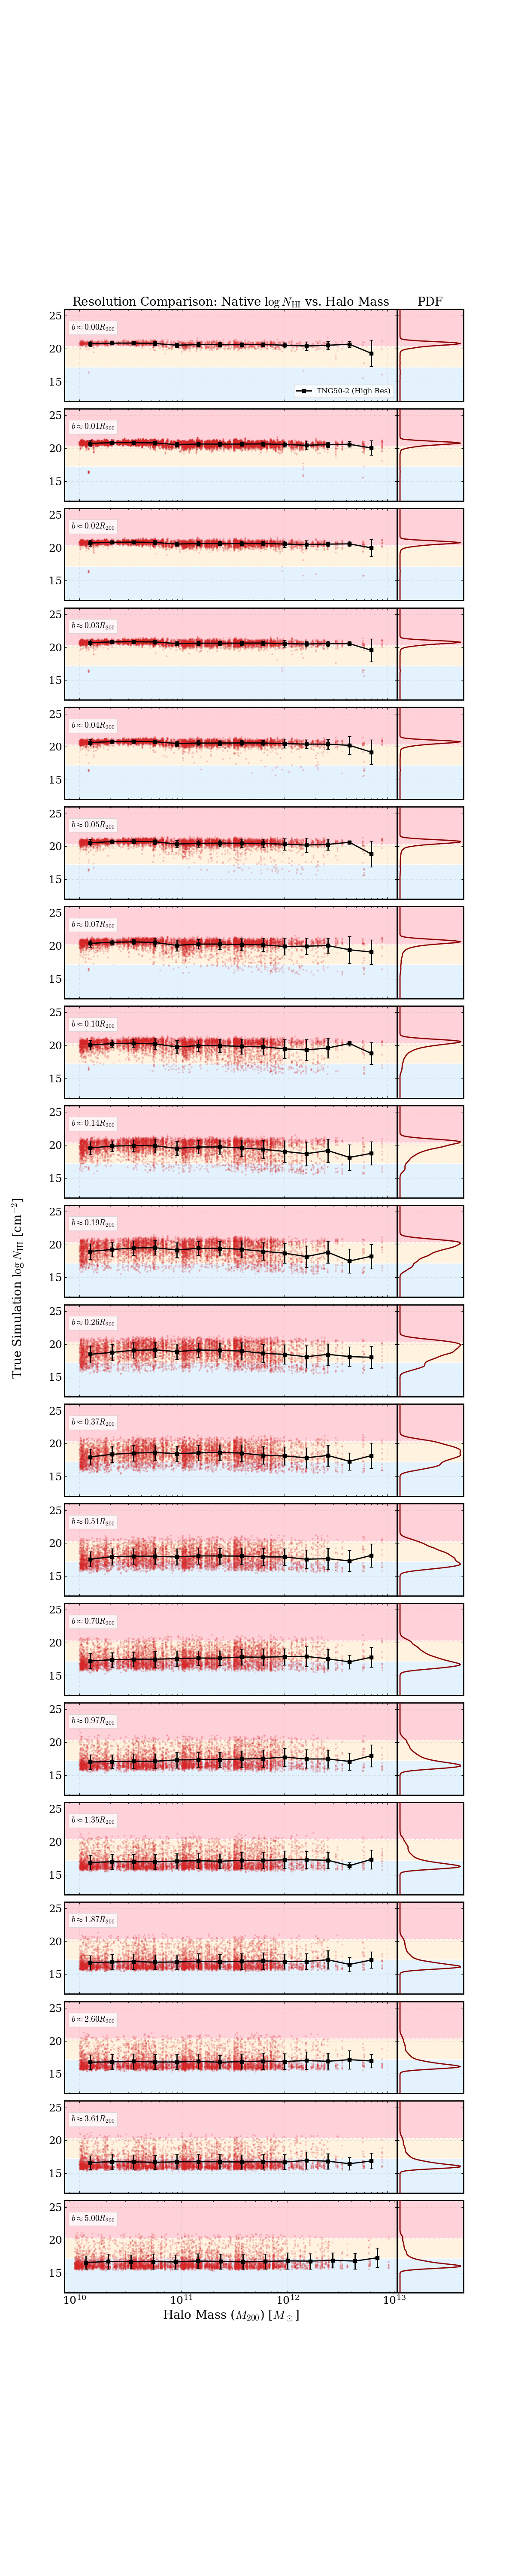

In [3]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import binned_statistic, gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# --- STYLE CONFIGURATION ---
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False, 
        'figure.frameon': True,
        'axes.linewidth': 2., 
        "axes.titlesize" : 20, 
        "axes.labelsize" : 20,
        "legend.fontsize" : 12, 
        'legend.fancybox': True, 
        'lines.linewidth': 2.5,
        'xtick.direction': 'in', 
        'ytick.direction': 'in',
        'xtick.top': True, 
        'ytick.right': True,
        'xtick.labelsize': 18, 
        'ytick.labelsize': 18
    }
    return font, rcnew

# Apply interactive backend and style
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# ==============================================================================
# CELL 1: MULTI-RESOLUTION DATA LOADING & PRE-PROCESSING (TNG50)
# ==============================================================================
# 1. Define a dictionary with your resolution models. 
DATA_FILES = {
    #'TNG50-4 (Low Res)':  'data_grid/TNG50-4_z3_579Halos_DLAMode_Stratified.pkl',
    #'TNG50-3 (Med Res)':  'data_grid/TNG50-3_z3_593Halos_DLAMode_Stratified.pkl',
    'TNG50-2 (High Res)': 'data_for_variance_50_2/TNG50-2_z3_637Halos_DLAMode_Stratified_run3_seed999.pkl'
}

HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# Dictionary to store the cleaned DataFrames
dfs_clean = {}
unique_radii = None

print("Loading Multi-Resolution Data...")
for model_name, file_path in DATA_FILES.items():
    if not os.path.exists(file_path):
        print(f" [!] Warning: {file_path} not found. Skipping {model_name}.")
        continue
        
    print(f" -> Processing {model_name}...")
    df = pd.read_pickle(file_path)
    df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
    
    # Clean data
    df_c = df.dropna(subset=['halo_mass_msun', 'eq_width', 'log_n_hi']).copy()
    df_c['r_mult_round'] = df_c['r_multiplier'].round(2)
    dfs_clean[model_name] = df_c
    
    # Extract unique radii (assuming all models share the same geometry)
    if unique_radii is None:
        unique_radii = np.sort(df_c['r_mult_round'].unique())

n_panels = len(unique_radii)
n_models = len(dfs_clean)

print("-" * 40)
print(f"Successfully loaded {n_models} resolution models.")
print(f"Impact parameters detected: {unique_radii}")

# ==============================================================================
# CELL 2: MULTI-RESOLUTION COMPARISON - NATIVE COLUMN DENSITY (SCATTER & PDF)
# ==============================================================================
fig_nhi, axes_nhi = plt.subplots(n_panels, 2, figsize=(12, 3 * n_panels), sharey=True, 
                                 gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.0, 'hspace': 0.08})
if n_panels == 1: axes_nhi = np.array([axes_nhi])

# Background region colors
c_forest = '#E3F2FD'  # Soft Blue
c_lls    = '#FFF3E0'  # Soft Orange
c_dla    = '#FFD1D8'  # Slightly darker Soft Red/Pink

# Style mapping for resolution models (Expandable)
# Index 0 (TNG50-4): Red mean, Dark Red PDF, Solid line
# Index 1 (TNG50-3): Blue mean, MidnightBlue PDF, Dashed line
# Index 2 (TNG50-2): Green mean, DarkGreen PDF, Dotted line
colors_scat = ['tab:red', 'tab:blue', 'tab:green']
colors_mean = ['black', 'dodgerblue', 'forestgreen']
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen']
line_styles = ['-', '--', ':']
markers     = ['s', 'o', '^']

for i, b_val in enumerate(unique_radii):
    ax_main, ax_hist = axes_nhi[i, 0], axes_nhi[i, 1]
    
    # 1. Background Regions
    for ax in [ax_main, ax_hist]:
        ax.axhspan(12.0, 17.2, color=c_forest, zorder=0)
        ax.axhspan(17.2, 20.3, color=c_lls, zorder=0)
        ax.axhspan(20.3, 26.0, color=c_dla, zorder=0)
        ax.axhline(17.2, color='white', ls='--', lw=1.5, zorder=0)
        ax.axhline(20.3, color='white', ls='--', lw=1.5, zorder=0)
        ax.grid(True, ls=':', alpha=0.4)

    # 2. Iterate through loaded models to overlay data
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_s = colors_scat[m_idx % len(colors_scat)]
        c_m = colors_mean[m_idx % len(colors_mean)]
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        mkr = markers[m_idx % len(markers)]
        
        df_b = df_model[df_model['r_mult_round'] == b_val]
        df_valid = df_b[(df_b['log_n_hi'] > 1.0) & (df_b['halo_mass_msun'] > 0.0)] 
        
        # Raw Scatter (Very low alpha)
        ax_main.scatter(df_b['halo_mass_msun'], df_b['log_n_hi'], 
                        s=5, alpha=0.15, color=c_s, zorder=1)
        
        if len(df_valid) > 0:
            # Binned Statistics
            bins = np.logspace(np.log10(df_valid['halo_mass_msun'].min()), np.log10(df_valid['halo_mass_msun'].max()), 15)
            means, edges, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'mean', bins=bins)
            stds, _, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'std', bins=bins)
            centers = np.sqrt(edges[:-1] * edges[1:])
            
            # Mean line overlay
            ax_main.errorbar(centers, means, yerr=stds, fmt=f'{mkr}{ls}', color=c_m, 
                             markersize=6, capsize=3, lw=2, zorder=5)
            
            # Marginal Distribution (PDF) - No fill, just lines for clean comparison
            if len(df_valid) > 1:
                kde = gaussian_kde(df_valid['log_n_hi'])
                y_grid = np.linspace(12.0, 26.0, 100)
                ax_hist.plot(kde(y_grid), y_grid, color=c_p, lw=2, ls=ls, zorder=3)

    # 3. Aesthetics
    ax_hist.set_xticks([])
    ax_main.set_xscale('log')
    if i < n_panels - 1: 
        ax_main.tick_params(labelbottom=False)
    
    ax_main.text(0.02, 0.85, rf"$b \approx {b_val:.2f} R_{{200}}$", 
                 transform=ax_main.transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgray'), va='top')
    
    if i == 0:
        ax_main.set_title(r"Resolution Comparison: Native $\log N_{\rm HI}$ vs. Halo Mass")
        ax_hist.set_title("PDF")
        
        # Build Legend for Models
        custom_lines = [Line2D([0], [0], color=colors_mean[m_idx % len(colors_mean)], 
                               lw=2, ls=line_styles[m_idx % len(line_styles)], 
                               marker=markers[m_idx % len(markers)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        ax_main.legend(handles=custom_lines, loc='lower right', ncol=2, frameon=True)

# Global Axis Labels
axes_nhi[-1, 0].set_xlabel(r"Halo Mass ($M_{200}$) [$M_\odot$]")
fig_nhi.text(0.02, 0.5, r"True Simulation $\log N_{\rm HI}$ [cm$^{-2}$]", va='center', rotation='vertical', fontsize=20)

first_df = list(dfs_clean.values())[0]
axes_nhi[-1, 0].set_xlim(first_df['halo_mass_msun'].min()*0.8, first_df['halo_mass_msun'].max()*1.2)
axes_nhi[-1, 0].set_ylim(12.0, 26.0)

plt.show()

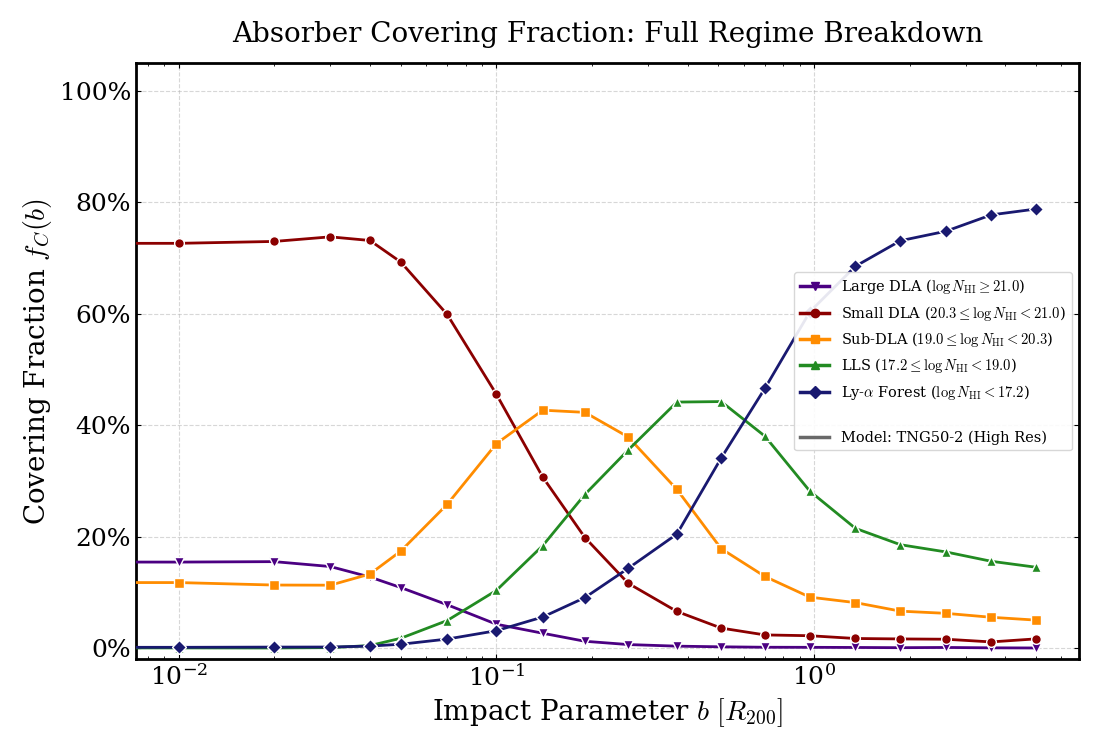

In [4]:
# ==============================================================================
# CELL 3: MULTI-RESOLUTION COVERING FRACTION vs IMPACT PARAMETER (FULL BREAKDOWN)
# ==============================================================================
fig_cov, ax_cov = plt.subplots(figsize=(11, 7.5))

# --- CATEGORY DEFINITIONS ---
# Based on standard N(HI) limits [atoms cm^-2]:
# Lyman-alpha forest : 0 to 1.6e17       (log N < 17.2)
# LLS                : 1.6e17 to 1e19    (17.2 <= log N < 19.0)
# Sub-DLA            : 1e19 to 2e20      (19.0 <= log N < 20.3)
# Small DLA          : 2e20 to 1e21      (20.3 <= log N < 21.0)
# Large DLA          : 1e21 to infinity  (log N >= 21.0)

cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v', 'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o', 'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's', 'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^', 'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D', 'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'}
}

# --- EXPLICIT LINE STYLE MAPPING ---
def get_line_style(model_string):
    """Forces explicit line styles based on the TNG resolution identifier."""
    if 'TNG50-2' in model_string: return '-'   # High Res
    if 'TNG50-3' in model_string: return '--'  # Med Res
    if 'TNG50-4' in model_string: return ':'   # Low Res
    return '-.' # Fallback

# --- POPULATE AND PLOT DATA ---
for model_name, df_model in dfs_clean.items():
    ls = get_line_style(model_name)
    
    # Initialize empty lists for fractions
    fracs = {key: [] for key in cat_styles.keys()}

    for b_val in unique_radii:
        df_b = df_model[df_model['r_mult_round'] == b_val]
        tot = len(df_b)
        
        if tot > 0:
            nhi = df_b['log_n_hi']
            fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
            fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
            fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
            fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
            fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
        else:
            for key in fracs.keys():
                fracs[key].append(0.0)

    # Plot curves for the current model
    for cat, f_list in fracs.items():
        ax_cov.plot(unique_radii, f_list, color=cat_styles[cat]['color'], lw=2.0, ls=ls, 
                    marker=cat_styles[cat]['marker'], ms=7, mec='white', zorder=4)

# --- COMPOSITE LEGEND ---
# 1. Absorber category legend
legend_elements = [Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], 
                          label=c['label']) for c in cat_styles.values()]
legend_elements.append(Line2D([0], [0], color='none', label=' ')) # Spacer

# 2. Resolution model legend
for model_name in dfs_clean.keys():
    legend_elements.append(Line2D([0], [0], color='dimgray', lw=2.5, 
                                  ls=get_line_style(model_name), label=f'Model: {model_name}'))

# --- AESTHETICS ---
ax_cov.grid(True, ls='--', alpha=0.5)
#ax_cov.set_xlim(-0.1, unique_radii.max() + 0.1)
ax_cov.set_xscale('log')
ax_cov.set_ylim(-0.02, 1.05)
ax_cov.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_cov.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_cov.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_cov.set_title(r'Absorber Covering Fraction: Full Regime Breakdown', pad=15)

ax_cov.legend(handles=legend_elements, loc='center right', frameon=True, 
              fontsize=10.5, edgecolor='lightgray', facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()



In [5]:
# ==============================================================================
# TERMINAL OUTPUT: PERCENTAGE TABLE AT MAX RADIUS
# ==============================================================================
max_b = unique_radii.max()

print("\n" + "="*85)
print(f" ABSORBER FRACTIONS AT IMPACT PARAMETER b = {max_b:.2f} R_200")
print("="*85)
print(f"{'Simulation Model':<20} | {'L-DLA':<9} | {'S-DLA':<9} | {'Sub-DLA':<9} | {'LLS':<9} | {'Forest':<9}")
print("-" * 85)

for model_name, df_model in dfs_clean.items():
    df_b = df_model[df_model['r_mult_round'] == max_b]
    tot = len(df_b)
    
    if tot > 0:
        nhi = df_b['log_n_hi']
        p_ldla = (len(nhi[nhi >= 21.0]) / tot) * 100
        p_sdla = (len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot) * 100
        p_sub  = (len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot) * 100
        p_lls  = (len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot) * 100
        p_for  = (len(nhi[nhi < 17.2]) / tot) * 100
        
        # Clean model name for display (removes the tag inside parentheses if exists)
        model_short = model_name.split('(')[0].strip()
        
        print(f"{model_short:<20} | {p_ldla:>8.2f}% | {p_sdla:>8.2f}% | {p_sub:>8.2f}% | {p_lls:>8.2f}% | {p_for:>8.2f}%")
    else:
        print(f"{model_name:<20} | No data available at this radius.")

print("="*85 + "\n")


 ABSORBER FRACTIONS AT IMPACT PARAMETER b = 5.00 R_200
Simulation Model     | L-DLA     | S-DLA     | Sub-DLA   | LLS       | Forest   
-------------------------------------------------------------------------------------
TNG50-2              |     0.03% |     1.66% |     5.02% |    14.51% |    78.78%



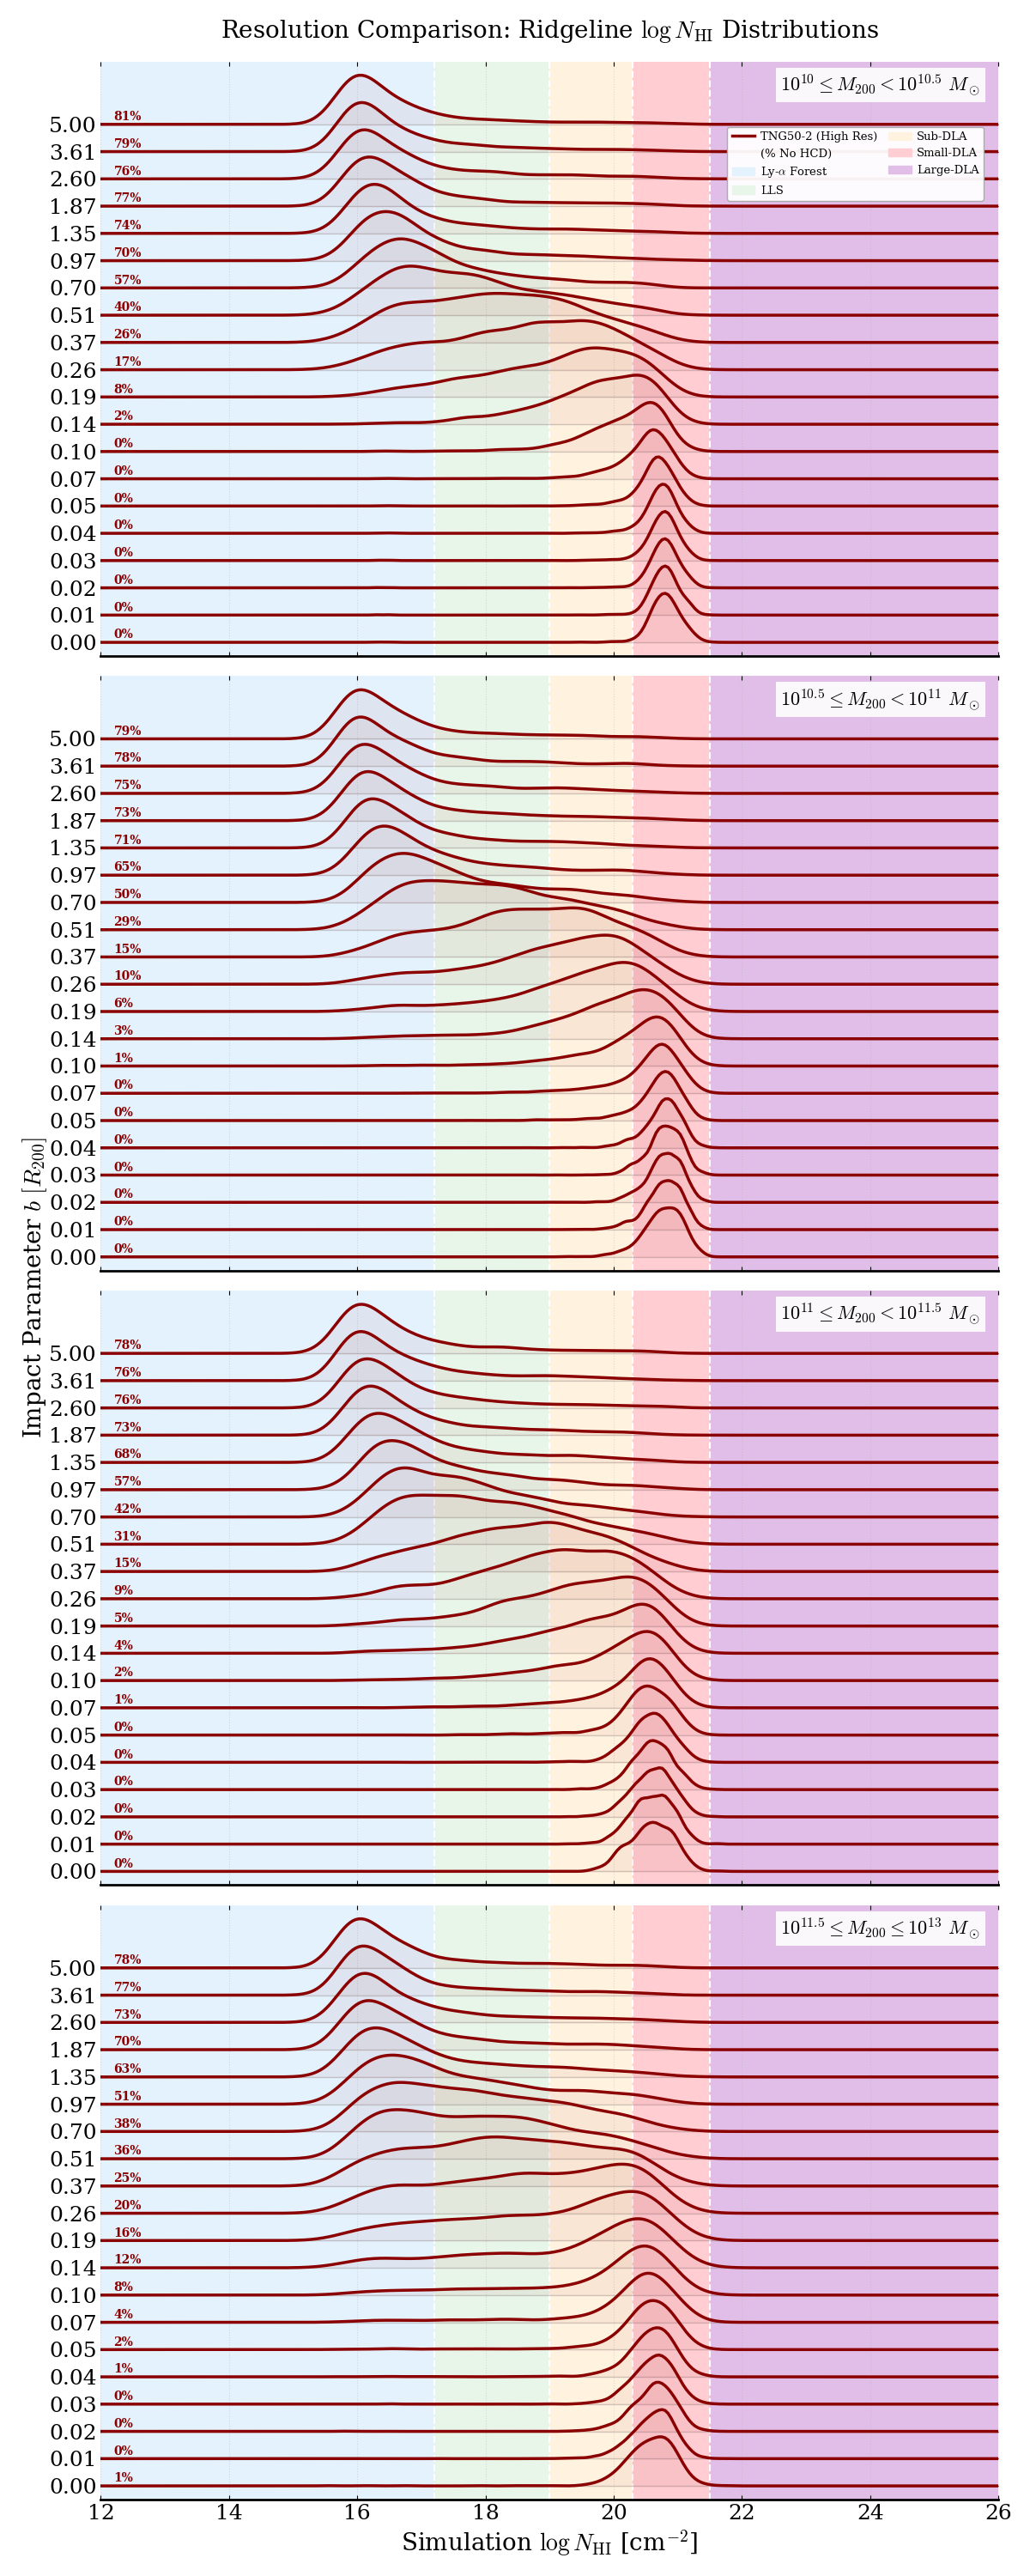

In [6]:
# ==============================================================================
# CELL 5: RADIAL PROFILES - RIDGELINE PLOT (JOYPLOT)
# ==============================================================================
# 1. Define Adjusted Mass Bins for TNG50
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**13.0]
mass_labels = [
    r'$10^{10} \leq M_{200} < 10^{10.5} \ M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11} \ M_\odot$',
    r'$10^{11} \leq M_{200} < 10^{11.5} \ M_\odot$',
    r'$10^{11.5} \leq M_{200} \leq 10^{13} \ M_\odot$'
]
n_bins = len(mass_labels)

fig_ridge, axes_ridge = plt.subplots(n_bins, 1, figsize=(12, 7.5 * n_bins), sharex=True)
if n_bins == 1: axes_ridge = np.array([axes_ridge])

colors_pdf  = ['darkred', 'midnightblue', 'darkgreen', 'indigo']
line_styles = ['-', '--', ':', '-.']

c_forest     = '#E3F2FD'  
c_lls        = '#E8F5E9'  
c_subdla     = '#FFF3E0'  
c_smalldla   = '#FFCDD2'  
c_largedla   = '#E1BEE7'  

overlap_factor = 1.8  

for i, (m_low, m_high, m_label) in enumerate(zip(mass_edges[:-1], mass_edges[1:], mass_labels)):
    ax = axes_ridge[i]
    
    # Background Regions
    ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls, zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla, zorder=0)
    ax.axvspan(20.3, 21.5, color=c_smalldla, zorder=0)
    ax.axvspan(21.5, 26.0, color=c_largedla, zorder=0)
    
    ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(19.0, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(21.5, color='white', ls='--', lw=1.5, zorder=0)
    
    ax.grid(axis='x', ls=':', alpha=0.4)
    ax.grid(axis='y', visible=False) 
    
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    ax.text(0.98, 0.95, m_label, transform=ax.transAxes, fontsize=16, ha='right',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'), zorder=30)

    y_ticks = []
    y_labels = []
    
    for i_b in reversed(range(len(unique_radii))):
        b_val = unique_radii[i_b]
        y_base = i_b  
        
        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
        
        text_x_start = 12.2 
        
        for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
            c_p = colors_pdf[m_idx % len(colors_pdf)]
            ls  = line_styles[m_idx % len(line_styles)]
            
            df_bin = df_model[(df_model['halo_mass_msun'] >= m_low) & (df_model['halo_mass_msun'] < m_high)]
            df_b = df_bin[df_bin['r_mult_round'] == b_val]
            
            tot = len(df_b)
            df_valid = df_b[df_b['log_n_hi'] > 1.0]
            
            if len(df_valid) > 2:
                kde = gaussian_kde(df_valid['log_n_hi'])
                x_grid = np.linspace(12.0, 26.0, 300)
                pdf = kde(x_grid)
                
                if pdf.max() > 0:
                    pdf_scaled = (pdf / pdf.max()) * overlap_factor
                    ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                    ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
            
            if tot > 0:
                p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                p_nohcd = 0.0
            
            ax.text(text_x_start + (m_idx * 1.0), y_base + 0.15, f"{p_nohcd:.0f}%", 
                    color=c_p, fontsize=10, fontweight='bold', zorder=20)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    if i == 0:
        ax.set_title(r"Resolution Comparison: Ridgeline $\log N_{\rm HI}$ Distributions", pad=20)
        
        custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                               lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        region_patches = [
            patches.Patch(color=c_forest, label=r'Ly-$\alpha$ Forest'), 
            patches.Patch(color=c_lls, label='LLS'), 
            patches.Patch(color=c_subdla, label='Sub-DLA'),
            patches.Patch(color=c_smalldla, label='Small-DLA'),
            patches.Patch(color=c_largedla, label='Large-DLA')
        ]
        
        custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(% No HCD)'))
        
        leg = ax.legend(handles=custom_lines + region_patches, 
                        loc='upper right', ncol=2, frameon=True, fontsize=9.5,                 
                        bbox_to_anchor=(0.99, 0.9), facecolor='white',            
                        framealpha=0.95, edgecolor='darkgray',        
                        columnspacing=1.0, handletextpad=0.5)            
        leg.set_zorder(100) 

axes_ridge[-1].set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
fig_ridge.text(0.02, 0.5, r'Impact Parameter $b \ [R_{200}]$', va='center', rotation='vertical', fontsize=20)
axes_ridge[-1].set_xlim(12.0, 26.0)

for ax in axes_ridge:
    ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()


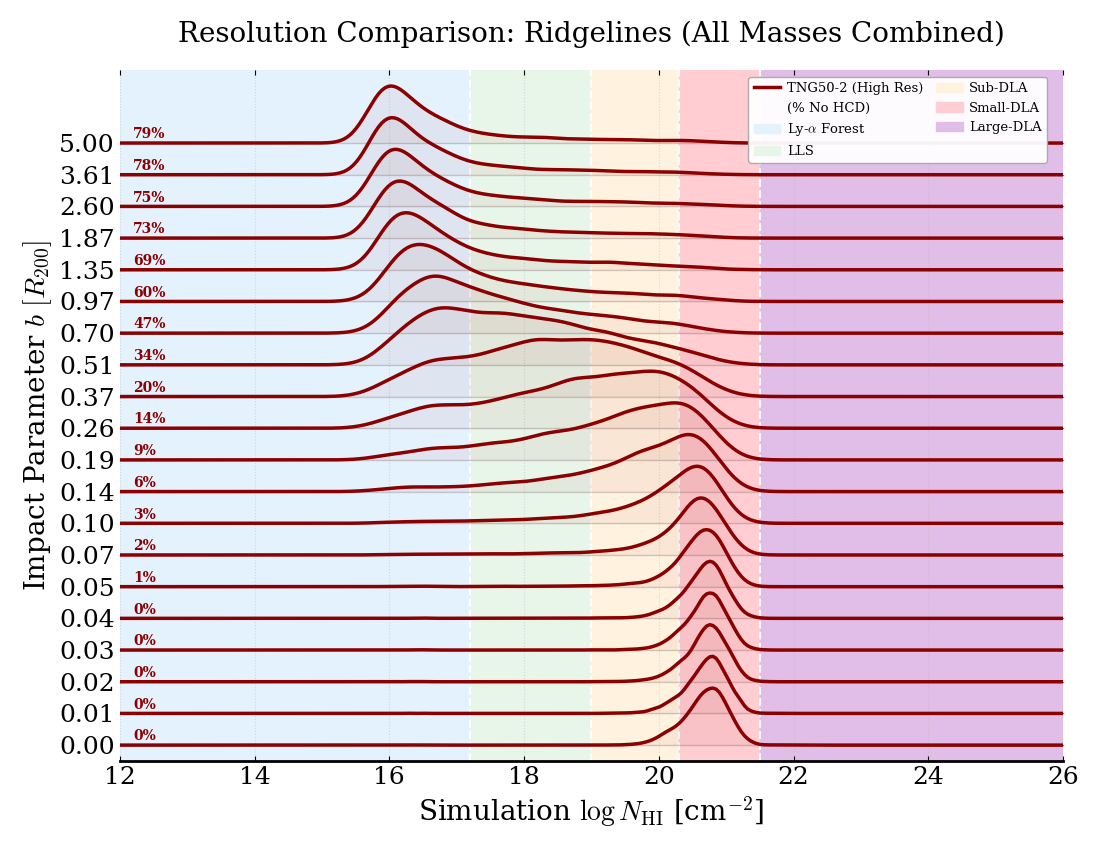

In [7]:
# ==============================================================================
# CELL 6: RADIAL PROFILES - RIDGELINE PLOT (ALL MASSES COMBINED)
# ==============================================================================
fig_ridge, ax = plt.subplots(figsize=(11, 8.5))

ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
ax.axvspan(17.2, 19.0, color=c_lls, zorder=0)
ax.axvspan(19.0, 20.3, color=c_subdla, zorder=0)
ax.axvspan(20.3, 21.5, color=c_smalldla, zorder=0)
ax.axvspan(21.5, 26.0, color=c_largedla, zorder=0)

ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(19.0, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(21.5, color='white', ls='--', lw=1.5, zorder=0)

ax.grid(axis='x', ls=':', alpha=0.4)
ax.grid(axis='y', visible=False) 

ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

y_ticks = []
y_labels = []

for i_b in reversed(range(len(unique_radii))):
    b_val = unique_radii[i_b]
    y_base = i_b  
    
    y_ticks.append(y_base)
    y_labels.append(f"{b_val:.2f}")
    ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
    
    text_x_start = 12.2 
    
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        
        df_b = df_model[df_model['r_mult_round'] == b_val]
        
        tot = len(df_b)
        df_valid = df_b[df_b['log_n_hi'] > 1.0]
        
        if len(df_valid) > 2:
            kde = gaussian_kde(df_valid['log_n_hi'])
            x_grid = np.linspace(12.0, 26.0, 300)
            pdf = kde(x_grid)
            
            if pdf.max() > 0:
                pdf_scaled = (pdf / pdf.max()) * overlap_factor
                ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
        
        if tot > 0:
            p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
        else:
            p_nohcd = 0.0
        
        ax.text(text_x_start + (m_idx * 1.0), y_base + 0.15, f"{p_nohcd:.0f}%", 
                color=c_p, fontsize=10, fontweight='bold', zorder=20)

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)

ax.set_title(r"Resolution Comparison: Ridgelines (All Masses Combined)", pad=20)

custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                       lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                for m_idx, model_name in enumerate(dfs_clean.keys())]

region_patches = [
    patches.Patch(color=c_forest, label=r'Ly-$\alpha$ Forest'), 
    patches.Patch(color=c_lls, label='LLS'), 
    patches.Patch(color=c_subdla, label='Sub-DLA'),
    patches.Patch(color=c_smalldla, label='Small-DLA'),
    patches.Patch(color=c_largedla, label='Large-DLA')
]

custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(% No HCD)'))

leg = ax.legend(handles=custom_lines + region_patches, loc='upper right', ncol=2, frameon=True, fontsize=9.5,                
                bbox_to_anchor=(0.99, 1.0), facecolor='white', framealpha=0.95,              
                edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5)            

leg.set_zorder(100) 

ax.set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
ax.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')
ax.set_xlim(12.0, 26.0)
ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout()
plt.show()

In [8]:
# ==============================================================================
# CELL 7: HALO COUNTS PER MASS BIN (UNIQUE HALOS)
# ==============================================================================
print("="*50)
print("             HALO COUNTS PER MASS BIN")
print("="*50)

# Utilizando os mesmos limites de massa das células de plotagem
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**13.0]
mass_labels_text = [
    '10^10 - 10^10.5',
    '10^10.5 - 10^11',
    '10^11 - 10^11.5',
    '10^11.5 - 10^13'
]

for model_name, df_model in dfs_clean.items():
    # Isola apenas halos únicos (uma linha por halo)
    df_unique = df_model.drop_duplicates(subset=['halo_id']).copy()
    
    # Categoriza a massa de cada halo nos bins definidos
    df_unique['mass_bin'] = pd.cut(df_unique['halo_mass_msun'], bins=mass_edges, labels=mass_labels_text)
    
    # Conta a quantidade de halos em cada categoria
    counts = df_unique['mass_bin'].value_counts(sort=False)
    
    print(f"\nSimulação: {model_name}")
    print(f"Total de halos extraídos: {len(df_unique)}")
    print("-" * 40)
    
    for label, count in counts.items():
        print(f"Bin {label:>15} M_sun : {count:>4} halos")
        
print("\n" + "="*50)

             HALO COUNTS PER MASS BIN

Simulação: TNG50-2 (High Res)
Total de halos extraídos: 637
----------------------------------------
Bin 10^10 - 10^10.5 M_sun :  150 halos
Bin 10^10.5 - 10^11 M_sun :  150 halos
Bin 10^11 - 10^11.5 M_sun :  150 halos
Bin 10^11.5 - 10^13 M_sun :  187 halos



In [ ]:
# ==============================================================================
# TESTE: Mode None vs Mode DLAs para o halo mais massivo, eixo X
# ==============================================================================
import numpy as np
import os
import sys
import h5py
import fake_spectra.spectra as spectra
import fake_spectra.unitsystem as unitsystem

In [ ]:


# --- CONFIGURATION (TNG50-2, snap 25, z=3) ---
BASE_PATH = "/home/STORAGE/TNG50-2"
SNAP_NUM = 25
SIM_TYPE = "TNG"

# TNG unit system
units = unitsystem.UnitSystem(
    UnitLength_in_cm=3.085678e21,   # 1 kpc
    UnitMass_in_g=1.989e43,         # 10^10 M_sun
    UnitVelocity_in_cm_per_s=1e5    # 1 km/s
)

# --- STEP 1: Find the most massive halo in the box ---
group_dir = os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}")
file0 = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")

with h5py.File(file0, 'r') as f:
    num_files = int(f['Header'].attrs['NumFiles'])
    hubble_h = float(f['Header'].attrs['HubbleParam'])

# Scan all chunks to find the most massive halo
all_masses = []
all_positions = []
all_global_ids = []
offset = 0

for i in range(num_files):
    fpath = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.{i}.hdf5")
    if not os.path.exists(fpath):
        continue
    with h5py.File(fpath, 'r') as f:
        if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
            continue
        m = f['Group']['Group_M_Crit200'][:]
        p = f['Group']['GroupPos'][:]
        ids = np.arange(offset, offset + len(m))
        all_masses.append(m)
        all_positions.append(p)
        all_global_ids.append(ids)
        offset += len(m)

all_masses = np.concatenate(all_masses)
all_positions = np.concatenate(all_positions)
all_global_ids = np.concatenate(all_global_ids)

# Most massive halo
idx_max = np.argmax(all_masses)
halo_id = int(all_global_ids[idx_max])
halo_cm = all_positions[idx_max].astype(np.float64)
halo_mass_msun = all_masses[idx_max] * 1e10 / hubble_h

print("=" * 65)
print("  MOST MASSIVE HALO IN TNG50-2 (z=3)")
print("=" * 65)
print(f"  Halo ID        : {halo_id}")
print(f"  Mass           : {halo_mass_msun:.3e} M_sun  (log = {np.log10(halo_mass_msun):.2f})")
print(f"  Position (code): [{halo_cm[0]:.3f}, {halo_cm[1]:.3f}, {halo_cm[2]:.3f}]")
print("=" * 65)

# --- STEP 2: Extract axis X with filter_mode="None" ---
cofm = np.array([halo_cm], dtype=np.float64)
axis = np.array([1], dtype=np.int32)  # 1 = X axis in fake_spectra

print("\n--- Extracting with filter_mode='None' (axis X) ---")
savefile_none = "test_none_axisX.hdf5"
ss_none = spectra.Spectra(
    SNAP_NUM, BASE_PATH,
    cofm=cofm, axis=axis,
    res=10.0,
    savefile=savefile_none,
    reload_file=True,
    kernel=None,
    MPI=None,
    quiet=False,
    filter_mode="None",
    units=units,
)
colden_none = ss_none.get_col_density("H", 1)[0]
tau_none = ss_none.get_tau("H", 1, 1215)[0]

total_none = np.sum(colden_none)
max_pixel_none = np.max(colden_none)
n_above_17 = np.sum(colden_none > 1e17)
n_above_19 = np.sum(colden_none > 1e19)
n_above_20 = np.sum(colden_none > 2e20)

print(f"\n  Total N_HI along LOS   : {total_none:.3e} cm^-2")
print(f"  log10(Total)           : {np.log10(total_none) if total_none > 0 else 0:.2f}")
print(f"  Max single pixel       : {max_pixel_none:.3e} cm^-2")
print(f"  log10(Max pixel)       : {np.log10(max_pixel_none) if max_pixel_none > 0 else 0:.2f}")
print(f"  Pixels > 1e17 (LLS)    : {n_above_17} / {len(colden_none)}")
print(f"  Pixels > 1e19 (sub-DLA): {n_above_19} / {len(colden_none)}")
print(f"  Pixels > 2e20 (DLA)    : {n_above_20} / {len(colden_none)}")

if os.path.exists(savefile_none):
    os.remove(savefile_none)

# --- STEP 3: Extract axis X with filter_mode="DLAs" ---
print("\n--- Extracting with filter_mode='DLAs' (axis X) ---")
savefile_dla = "test_dla_axisX.hdf5"
ss_dla = spectra.Spectra(
    SNAP_NUM, BASE_PATH,
    cofm=cofm, axis=axis,
    res=10.0,
    savefile=savefile_dla,
    reload_file=True,
    kernel=None,
    MPI=None,
    quiet=False,
    filter_mode="DLAs",
    dla_phys_thresh="auto",
    units=units,
)
colden_dla = ss_dla.get_col_density("H", 1)[0]
tau_dla = ss_dla.get_tau("H", 1, 1215)[0]

total_dla = np.sum(colden_dla)
max_pixel_dla = np.max(colden_dla)

print(f"\n  Total N_HI along LOS   : {total_dla:.3e} cm^-2")
print(f"  log10(Total)           : {np.log10(total_dla) if total_dla > 0 else 0:.2f}")
print(f"  Max single pixel       : {max_pixel_dla:.3e} cm^-2")

if os.path.exists(savefile_dla):
    os.remove(savefile_dla)

# --- STEP 4: Also test axes Y and Z for comparison ---
for ax_label, ax_int in [("Y", 2), ("Z", 3)]:
    print(f"\n--- Extracting with filter_mode='None' (axis {ax_label}) ---")
    axis_test = np.array([ax_int], dtype=np.int32)
    sf = f"test_none_axis{ax_label}.hdf5"
    ss_test = spectra.Spectra(
        SNAP_NUM, BASE_PATH,
        cofm=cofm, axis=axis_test,
        res=10.0,
        savefile=sf,
        reload_file=True,
        kernel=None,
        MPI=None,
        quiet=True,
        filter_mode="None",
        units=units,
    )
    cd_test = ss_test.get_col_density("H", 1)[0]
    total_test = np.sum(cd_test)
    print(f"  Total N_HI  : {total_test:.3e}  (log = {np.log10(total_test) if total_test > 0 else 0:.2f})")
    print(f"  Max pixel   : {np.max(cd_test):.3e}")
    print(f"  Pixels > 1e17: {np.sum(cd_test > 1e17)}")
    print(f"  Pixels > 1e19: {np.sum(cd_test > 1e19)}")
    
    print(f"\n--- Extracting with filter_mode='DLAs' (axis {ax_label}) ---")
    sf2 = f"test_dla_axis{ax_label}.hdf5"
    ss_test2 = spectra.Spectra(
        SNAP_NUM, BASE_PATH,
        cofm=cofm, axis=axis_test,
        res=10.0,
        savefile=sf2,
        reload_file=True,
        kernel=None,
        MPI=None,
        quiet=True,
        filter_mode="DLAs",
        dla_phys_thresh="auto",
        units=units,
    )
    cd_test2 = ss_test2.get_col_density("H", 1)[0]
    total_test2 = np.sum(cd_test2)
    print(f"  Total N_HI  : {total_test2:.3e}  (log = {np.log10(total_test2) if total_test2 > 0 else 0:.2f})")
    print(f"  Max pixel   : {np.max(cd_test2):.3e}")
    
    if os.path.exists(sf):
        os.remove(sf)
    if os.path.exists(sf2):
        os.remove(sf2)

# --- STEP 5: Summary table ---
print("\n" + "=" * 65)
print("  SUMMARY: AXIS X — None vs DLAs")
print("=" * 65)
print(f"  {'Metric':<30} {'None':>15} {'DLAs':>15}")
print(f"  {'-'*60}")
print(f"  {'Total N_HI':<30} {total_none:>15.3e} {total_dla:>15.3e}")
print(f"  {'log10(Total)':<30} {(np.log10(total_none) if total_none > 0 else 0):>15.2f} {(np.log10(total_dla) if total_dla > 0 else 0):>15.2f}")
print(f"  {'Max pixel':<30} {max_pixel_none:>15.3e} {max_pixel_dla:>15.3e}")
print(f"  {'Pixels > 1e17':<30} {n_above_17:>15d} {'N/A':>15}")
print(f"  {'Pixels > 1e19':<30} {n_above_19:>15d} {'N/A':>15}")
print(f"  {'Pixels > 2e20':<30} {n_above_20:>15d} {'N/A':>15}")
print("=" * 65)

if total_dla == 0 and total_none > 1e17:
    print(f"\n  ❌ CONFIRMED: DLA filter is INCORRECTLY zeroing this skewer.")
    print(f"     Mode 'None' shows {n_above_17} pixels above LLS threshold.")
    if n_above_19 > 0 and n_above_19 < 20:
        print(f"     This is a COHERENT DENSE STRUCTURE ({n_above_19} pixels > 1e19).")
        print(f"     The fallback fix is REQUIRED.")
    elif n_above_19 == 0 and n_above_17 > 50:
        print(f"     This is DIFFUSE accumulation ({n_above_17} pixels > 1e17, spread out).")
        print(f"     The filter may be correct. Inspect the pixel distribution.")
    else:
        print(f"     Run visual inspection to determine if structure is coherent.")
elif total_dla > 0:
    print(f"\n  ✅ DLA filter found structure. No fallback needed for this skewer.")